# Feedback vertex set control of a 21-state mammalian circadian rhythm model

**Reproducible Python/Jupyter implementation.** This notebook translates the user's earlier MATLAB/Julia implementation to Python. It numerically studies **constant-value feedback-vertex-set (FVS) control** of the 21-dimensional ODE model and compares controlled dynamics with an uncontrolled run.

**Where the model comes from.** Mirsky *et al.* (2009) developed the mammalian circadian clock model. The **specific 132-parameter set and FVS experiment used here** follow Fiedler, Mochizuki, Kurosawa and Saito (2013), *Dynamics and control at feedback vertex sets I*, Sec. 7.3 and Appendix 9. We do **not** claim the biological model or FVS-control principle as original.

**Correction relative to the uploaded Julia code:** the second activating Hill term in the `rorc` mRNA equation depends on the **`RORC` protein**, not `CLKBMAL1`. See Eq. (9.8) of the Fiedler *et al.* appendix. The equilibrium is therefore **recomputed** rather than using the four-decimal old target uncritically.

**Definitions:** The directed influence graph has an edge `u → v` exactly when state `u` occurs in the formula for `d(v)/dt`, excluding self-dependence. For a chosen FVS, each controlled state is instantaneously set to its equilibrium value and held there. Only the remaining components are integrated. This is an idealized **state-clamping experiment**, not an actuator model or a proof of global convergence.

**Sources:**
- Mirsky et al. (2009): https://pmc.ncbi.nlm.nih.gov/articles/PMC2699375/
- Fiedler et al. (2013), full model equations and parameters (Appendix 9): https://dynamics.mi.fu-berlin.de/preprints/FiedlerMochizukiKurosawaSaito%202013-03-30%20submit%20final.pdf

**Notebook outline:** parameters → nonlinear equations → equilibrium and Jacobian → directed graph/FVS checks → controlled/uncontrolled ODE simulations → convergence metrics/figures → optional RK4 comparison.

In [1]:
# Python packages: numpy, scipy, networkx, matplotlib, pandas.
# From a terminal: pip install -r requirements.txt

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root

np.set_printoptions(precision=9, suppress=True)
OUTPUT = Path("outputs")
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Python {sys.version.split()[0]}; NumPy {np.__version__}; SciPy and other libraries imported")

Python 3.13.5; NumPy 2.3.5; SciPy and other libraries imported


## 1. States and published parameter values

Uppercase labels denote proteins, lowercase labels mRNA species, and concatenated labels protein complexes. The ordering exactly matches the earlier Julia code. Parameters below are inherited from the published parameter set reproduced in the uploaded Julia source; they are **not fitted** in this notebook.

In [2]:
STATE_NAMES = [
    "PER1", "PER2", "per1", "per2", "CRY1", "CRY2", "cry1", "cry2",
    "PER1CRY1", "PER1CRY2", "PER2CRY1", "PER2CRY2",
    "REVERB", "reverb", "RORC", "rorc", "CLK", "clk", "BMAL1", "bmal1", "CLKBMAL1"
]
STATE_INDEX = {name: i for i, name in enumerate(STATE_NAMES)}
N = len(STATE_NAMES)
assert N == 21 and len(STATE_INDEX) == 21

# Rounded equilibrium supplied in the *older* code. It is ONLY a root-solver initial guess.
OLD_ROUNDED_GUESS = np.array([
    0.1229, 0.4361, 0.1040, 0.5496, 2.1465, 1.4523, 0.1700, 5.0701,
    0.7137, 0.3011, 2.6030, 1.0467, 1.4131, 0.2738, 0.0971, 0.2326,
    0.6503, 0.3251, 1.2300, 0.7011, 1.6326
], dtype=float)
assert OLD_ROUNDED_GUESS.shape == (21,)


In [3]:
# 132 values, transcribed from the uploaded Julia version of the 2013 parameters.
P = {
    "v0_per1": 0.000001,
    "v1_per1": 3.0,
    "KA1_per1": 1.98,
    "na1_per1": 2.0,
    "KI1_per1": 1.07,

    "KI2_per1": 3.96,
    "KI3_per1": 1.68,
    "KI4_per1": 3.11,
    "ni1_per1": 2.0,
    "ni2_per1": 1.0,

    "ni3_per1": 2.0,
    "ni4_per1": 4.0,
    "km_per1": 2.18,
    "v0_per2": 0.09,
    "v1_per2": 3.29,

    "KA1_per2": 1.90,
    "na1_per2": 10.0,
    "KI1_per2": 4.51,
    "KI2_per2": 2.98,
    "KI3_per2": 2.24,

    "KI4_per2": 3.31,
    "ni1_per2": 1.0,
    "ni2_per2": 1.0,
    "ni3_per2": 9.0,
    "ni4_per2": 8.0,

    "km_per2": 0.20,
    "v0_cry1": 0.26,
    "v1_cry1": 2.44,
    "v2_cry1": 2.89,
    "KA1_cry1": 1.46,

    "KA2_cry1": 3.76,
    "na1_cry1": 4.91,
    "na2_cry1": 3.01,
    "KI1_cry1": 0.03,
    "KI2_cry1": 0.77,

    "KI3_cry1": 3.59,
    "KI4_cry1": 3.44,
    "KI5_cry1": 2.82,
    "ni1_cry1": 1.0,
    "ni2_cry1": 1.0,

    "ni3_cry1": 6.0,
    "ni4_cry1": 4.0,
    "ni5_cry1": 2.24,
    "km_cry1": 0.22,
    "v0_cry2": 1.29,

    "v1_cry2": 2.72,
    "v2_cry2": 0.10,
    "KA1_cry2": 0.69,
    "KA2_cry2": 2.96,
    "na1_cry2": 4.39,

    "na2_cry2": 4.43,
    "KI1_cry2": 4.63,
    "KI2_cry2": 2.95,
    "KI3_cry2": 3.57,
    "KI4_cry2": 2.75,

    "KI5_cry2": 3.97,
    "ni1_cry2": 1.0,
    "ni2_cry2": 1.0,
    "ni3_cry2": 4.0,
    "ni4_cry2": 8.0,

    "ni5_cry2": 1.75,
    "km_cry2": 0.41,
    "v1_reverb": 11.06,
    "KA1_reverb": 3.15,
    "na1_reverb": 4.40,

    "KI1_reverb": 3.56,
    "KI2_reverb": 3.62,
    "KI3_reverb": 4.71,
    "KI4_reverb": 1.23,
    "ni1_reverb": 0.15,

    "ni2_reverb": 0.30,
    "ni3_reverb": 7.0,
    "ni4_reverb": 7.0,
    "km_reverb": 0.60,
    "v0_clk": 3.98,

    "v1_clk": 3.36,
    "KA1_clk": 1.59,
    "na1_clk": 3.50,
    "KI1_clk": 0.83,
    "ni1_clk": 1.96,

    "km_clk": 3.19,
    "v0_bmal1": 1.98,
    "v1_bmal1": 4.12,
    "KA1_bmal1": 2.59,
    "na1_bmal1": 4.13,

    "KI1_bmal1": 2.47,
    "ni1_bmal1": 0.02,
    "km_bmal1": 1.42,
    "v0_rorc": 0.06,
    "v1_rorc": 3.55,

    "v2_rorc": 0.46,
    "KA1_rorc": 4.30,
    "KA2_rorc": 4.89,
    "na1_rorc": 1.57,
    "na2_rorc": 0.56,

    "KI1_rorc": 3.49,
    "KI2_rorc": 2.34,
    "KI3_rorc": 2.71,
    "KI4_rorc": 2.09,
    "KI5_rorc": 3.36,

    "ni1_rorc": 1.0,
    "ni2_rorc": 1.0,
    "ni3_rorc": 7.0,
    "ni4_rorc": 7.0,
    "ni5_rorc": 4.33,

    "km_rorc": 1.50,
    "t_per1": 3.05,
    "kp_PER1": 2.58,
    "t_per2": 2.38,
    "kp_PER2": 3.0,

    "t_cry1": 3.94,
    "kp_CRY1": 0.312,
    "t_cry2": 1.69,
    "kp_CRY2": 5.9,
    "t_reverb": 1.60,

    "kp_REVERB": 0.31,
    "t_clk": 3.04,
    "kp_CLK": 1.52,
    "kp_BMAL1": 2.28,
    "t_bmal1": 4.00,

    "kp_RORC": 3.33,
    "t_rorc": 1.39,
    "a_CB1": 1.98,
    "d_CB1": 0.97,
    "a_PC11": 3.57,

    "a_PC12": 3.12,
    "a_PC21": 3.81,
    "a_PC22": 4.0,
    "d_PC11": 1.32,
    "d_PC12": 1.85,

    "d_PC21": 1.37,
    "d_PC22": 2.42,
}
assert len(P) == 132
print(f"Loaded {len(P)} published parameters")

Loaded 132 published parameters


## 2. Nonlinear right-hand side: all 21 ODEs

These equations use activation and inhibition Hill functions,

\[H_+(z;K,n)=\frac{z^n}{K^n+z^n}, \qquad H_-(z;K,n)=\frac{K^n}{K^n+z^n}.\]

**Domain:** the biological states and the Hill-function inputs are nonnegative. Some exponents are nonintegers, so arbitrary negative numerical states are not physically or mathematically meaningful here. For numerical robustness, Hill evaluations use `max(z, 0)` when an adaptive solver temporarily probes a slightly negative internal stage. This extends the function outside its biological domain only for numerical integration; accepted trajectory values are checked for nonnegativity.

We use the same `PER1CRY1`, etc. names for the four protein complexes, and `CLKBMAL1` for the fifth. The `rorc` activation term from `RORC` is explicitly marked below.

In [4]:
def hill_activation(z, K, n):
    """Activating Hill factor H_+(z; K, n), for z >= 0."""
    # Extend Hill terms smoothly enough for temporary negative solver trial stages.
    # On the nonnegative physical state space, this makes NO change to the ODE.
    z = max(0.0, float(z))
    return z**n / (K**n + z**n)


def hill_repression(z, K, n):
    """Repressing Hill factor H_-(z; K, n), for z >= 0."""
    z = max(0.0, float(z))
    return K**n / (K**n + z**n)


def circadian_rhs(t, x):
    """Published 21-state ODE right-hand side; state ordering is STATE_NAMES.

    The parameter values are from Fiedler et al. (2013), Appendix 9.2.
    Note: no control is applied here. For controlled dynamics see `controlled_rhs`.
    """
    x = np.asarray(x, dtype=float)
    if x.shape != (N,):
        raise ValueError(f"Expected exactly {N} states, got {x.shape}")
    # Negative RK trial stages are supported only through the positive-part
    # extension of the Hill terms; accepted trajectories are checked later.
    (PER1, PER2, per1, per2, CRY1, CRY2, cry1, cry2,
     PC11, PC12, PC21, PC22, REVERB, reverb, RORC, rorc,
     CLK, clk, BMAL1, bmal1, CB1) = x
    p = P

    # Protein-complex kinetics: protein binding and dissociation.
    pc11 = p["a_PC11"] * PER1 * CRY1 - p["d_PC11"] * PC11
    pc12 = p["a_PC12"] * PER1 * CRY2 - p["d_PC12"] * PC12
    pc21 = p["a_PC21"] * PER2 * CRY1 - p["d_PC21"] * PC21
    pc22 = p["a_PC22"] * PER2 * CRY2 - p["d_PC22"] * PC22
    cb1 = p["a_CB1"] * CLK * BMAL1 - p["d_CB1"] * CB1

    # Protein synthesis, complex formation/dissociation, and degradation.
    dPER1 = p["t_per1"] * per1 - p["a_PC11"] * PER1 * CRY1 - p["a_PC12"] * PER1 * CRY2 \
            + p["d_PC11"] * PC11 + p["d_PC12"] * PC12 - p["kp_PER1"] * PER1
    dPER2 = p["t_per2"] * per2 - p["a_PC21"] * PER2 * CRY1 - p["a_PC22"] * PER2 * CRY2 \
            + p["d_PC21"] * PC21 + p["d_PC22"] * PC22 - p["kp_PER2"] * PER2
    dCRY1 = p["t_cry1"] * cry1 - p["a_PC11"] * PER1 * CRY1 - p["a_PC21"] * PER2 * CRY1 \
            + p["d_PC11"] * PC11 + p["d_PC21"] * PC21 - p["kp_CRY1"] * CRY1
    dCRY2 = p["t_cry2"] * cry2 - p["a_PC12"] * PER1 * CRY2 - p["a_PC22"] * PER2 * CRY2 \
            + p["d_PC12"] * PC12 + p["d_PC22"] * PC22 - p["kp_CRY2"] * CRY2
    dREVERB = p["t_reverb"] * reverb - p["kp_REVERB"] * REVERB
    dRORC = p["t_rorc"] * rorc - p["kp_RORC"] * RORC
    dCLK = p["t_clk"] * clk - p["a_CB1"] * CLK * BMAL1 \
           + p["d_CB1"] * CB1 - p["kp_CLK"] * CLK
    dBMAL1 = p["t_bmal1"] * bmal1 - p["a_CB1"] * CLK * BMAL1 \
             + p["d_CB1"] * CB1 - p["kp_BMAL1"] * BMAL1

    complexes = (PC11, PC12, PC21, PC22)

    def inhibition_product(gene, extra_reverb=False):
        """Product of Hill inhibition factors from the four PER/CRY complexes."""
        values = [hill_repression(z, p[f"KI{i}_{gene}"], p[f"ni{i}_{gene}"])
                  for i, z in enumerate(complexes, 1)]
        if extra_reverb:
            values.append(hill_repression(REVERB, p[f"KI5_{gene}"], p[f"ni5_{gene}"]))
        return float(np.prod(values))

    # per1 and per2 mRNA: CLK/BMAL1 activation and 4 complex inhibitions.
    dper1 = (p["v0_per1"] + p["v1_per1"] * hill_activation(
        CB1, p["KA1_per1"], p["na1_per1"])) * inhibition_product("per1") - p["km_per1"] * per1
    dper2 = (p["v0_per2"] + p["v1_per2"] * hill_activation(
        CB1, p["KA1_per2"], p["na1_per2"])) * inhibition_product("per2") - p["km_per2"] * per2

    # cry1, cry2 mRNA: dual activation (CLK/BMAL1 and RORC), 5 inhibitions.
    dcry1 = (p["v0_cry1"]
             + p["v1_cry1"] * hill_activation(CB1, p["KA1_cry1"], p["na1_cry1"])
             + p["v2_cry1"] * hill_activation(RORC, p["KA2_cry1"], p["na2_cry1"])) \
            * inhibition_product("cry1", True) - p["km_cry1"] * cry1
    dcry2 = (p["v0_cry2"]
             + p["v1_cry2"] * hill_activation(CB1, p["KA1_cry2"], p["na1_cry2"])
             + p["v2_cry2"] * hill_activation(RORC, p["KA2_cry2"], p["na2_cry2"])) \
            * inhibition_product("cry2", True) - p["km_cry2"] * cry2

    # reverb and rorc mRNA: reverb has 4 inhibitory complexes, rorc has 5.
    dreverb = p["v1_reverb"] * hill_activation(
        CB1, p["KA1_reverb"], p["na1_reverb"]) * inhibition_product("reverb") \
        - p["km_reverb"] * reverb
    drorc = (p["v0_rorc"]
             + p["v1_rorc"] * hill_activation(CB1, p["KA1_rorc"], p["na1_rorc"])
             # IMPORTANT: this is RORC, NOT CB1, in the published equation (9.8).
             + p["v2_rorc"] * hill_activation(RORC, p["KA2_rorc"], p["na2_rorc"])) \
            * inhibition_product("rorc", True) - p["km_rorc"] * rorc

    # clk and bmal1 mRNA: RORC activation, REVERB inhibition.
    dclk = (p["v0_clk"] + p["v1_clk"] * hill_activation(
        RORC, p["KA1_clk"], p["na1_clk"])) * hill_repression(
        REVERB, p["KI1_clk"], p["ni1_clk"]) - p["km_clk"] * clk
    dbmal1 = (p["v0_bmal1"] + p["v1_bmal1"] * hill_activation(
        RORC, p["KA1_bmal1"], p["na1_bmal1"])) * hill_repression(
        REVERB, p["KI1_bmal1"], p["ni1_bmal1"]) - p["km_bmal1"] * bmal1

    return np.array([
        dPER1, dPER2, dper1, dper2, dCRY1, dCRY2, dcry1, dcry2,
        pc11, pc12, pc21, pc22, dREVERB, dreverb, dRORC, drorc,
        dCLK, dclk, dBMAL1, dbmal1, cb1
    ], dtype=float)

# Basic sanity checks on the state-space implementation.
assert np.isfinite(circadian_rhs(0.0, np.ones(N))).all()
assert circadian_rhs(0.0, np.ones(N)).shape == (21,)
print("All 21 equations evaluated successfully at a positive test state.")

All 21 equations evaluated successfully at a positive test state.


## 3. Solve for a stationary state and check local stability

We solve \(f(x^*)=0\) numerically using the previously reported four-decimal solution **only as an initial guess**. We check the full residual and positivity. A root-finding algorithm may converge to one equilibrium without finding all equilibria; the output is not a proof of uniqueness. We also compute a finite-difference Jacobian to examine *local* stability.

The 2013 paper reports that its chosen parameters admit an **unstable stationary state** as well as periodic long-term behavior. In this notebook, `TARGET_EQUILIBRIUM` names the stationary state, **not an uncontrolled attractor**.

In [5]:
res = root(lambda z: circadian_rhs(0, z), OLD_ROUNDED_GUESS,
           method="hybr", tol=1e-12, options={"maxfev": 10000})
TARGET_EQUILIBRIUM = np.asarray(res.x, dtype=float)
residual = float(np.max(np.abs(circadian_rhs(0, TARGET_EQUILIBRIUM))))
if not np.all(TARGET_EQUILIBRIUM > 0) or residual > 1e-9:
    raise RuntimeError(f"Equilibrium refinement failed: solver={res.message}, residual={residual}")
print(f"Solver message: {res.message}")
print(f"Maximum absolute equilibrium residual: {residual:.3e}")
print(f"Old rounded target residual (corrected model): "
      f"{np.max(np.abs(circadian_rhs(0, OLD_ROUNDED_GUESS))):.3e}")
display(pd.DataFrame({"state": STATE_NAMES,
                      "old_rounded_guess": OLD_ROUNDED_GUESS,
                      "recomputed_equilibrium": TARGET_EQUILIBRIUM}))


def finite_difference_jacobian(fun, x, relstep=1e-5):
    """Numerical central-difference Jacobian for a vector-valued function."""
    x = np.asarray(x, float)
    J = np.empty((len(x), len(x)))
    for j in range(len(x)):
        h = relstep * max(1.0, abs(x[j]))
        xp, xm = x.copy(), x.copy()
        xp[j] += h
        xm[j] -= h
        J[:, j] = (fun(xp) - fun(xm)) / (2 * h)
    return J

J = finite_difference_jacobian(lambda z: circadian_rhs(0, z), TARGET_EQUILIBRIUM)
evals = np.linalg.eigvals(J)
print("Spectral abscissa of uncontrolled equilibrium:", f"{max(evals.real):.7f}")
print("Largest-real-part eigenvalues:",
      sorted(evals, key=lambda z: z.real, reverse=True)[:4])

Solver message: The solution converged.
Maximum absolute equilibrium residual: 1.776e-15
Old rounded target residual (corrected model): 4.692e-02


,state,old_rounded_guess,recomputed_equilibrium
0,PER1,0.1229,0.122947
1,PER2,0.4361,0.436053
2,per1,0.1040,0.104001
3,per2,0.5496,0.549646
4,CRY1,2.1465,2.146473
5,CRY2,1.4523,1.452278
6,cry1,0.1700,0.169974
7,cry2,5.0701,5.070084
8,PER1CRY1,0.7137,0.713734
9,PER1CRY2,0.3011,0.301127


Spectral abscissa of uncontrolled equilibrium: 0.0028234
Largest-real-part eigenvalues: [np.complex128(0.0028234074346826232+0.2859568045316339j), np.complex128(0.0028234074346826232-0.2859568045316339j), np.complex128(-0.068908775717996+0.6815249157549516j), np.complex128(-0.068908775717996-0.6815249157549516j)]


## 4. Directed influence graph and six FVS candidates

The graph encodes **off-diagonal** state dependencies. We deliberately omit the trivial self-dependence that appears in many degradation equations: if self-loops were included, every such vertex would be a one-cycle and the FVS interpretation would change.

The adjacency structure is independently kept as a transparent mapping of equation targets to influencing state variables. The notebook checks its vertex/edge counts and provides a **numerical finite-difference dependency audit** at several positive states; this audit is a useful diagnostic, but numerical derivatives cannot substitute for symbolic checking of the equations.

A proposed FVS is tested by removing its vertices and checking whether the remaining digraph is acyclic. **Inclusion-minimal** means no single vertex can be removed from that FVS while preserving this property. This is not the same as proving that its cardinality is minimum.

In [6]:
FVS_SETS = [
    ["PER1", "PER2", "CRY1", "CRY2", "CLK", "BMAL1", "RORC"],
    ["PER1", "PER2", "CRY1", "CRY2", "BMAL1", "CLKBMAL1", "RORC"],
    ["PER1", "PER2", "CRY1", "CRY2", "CLK", "CLKBMAL1", "RORC"],
    ["PER1", "PER2", "CRY1", "CRY2", "CLK", "BMAL1", "rorc"],
    ["PER1", "PER2", "CRY1", "CRY2", "BMAL1", "CLKBMAL1", "rorc"],
    ["PER1", "PER2", "CRY1", "CRY2", "CLK", "CLKBMAL1", "rorc"],
]
INFLUENCERS = {
    'PER1': ['PER1CRY1', 'PER1CRY2', 'per1', 'CRY1', 'CRY2'],
    'PER2': ['PER2CRY1', 'PER2CRY2', 'per2', 'CRY1', 'CRY2'],
    'per1': ['PER1CRY1', 'PER1CRY2', 'PER2CRY1', 'PER2CRY2', 'CLKBMAL1'],
    'per2': ['PER1CRY1', 'PER1CRY2', 'PER2CRY1', 'PER2CRY2', 'CLKBMAL1'],
    'CRY1': ['PER1', 'PER2', 'cry1', 'PER1CRY1', 'PER2CRY1'],
    'CRY2': ['PER1', 'PER2', 'cry2', 'PER1CRY2', 'PER2CRY2'],
    'cry1': ['PER1CRY1', 'PER1CRY2', 'PER2CRY1', 'PER2CRY2', 'CLKBMAL1', 'REVERB', 'RORC'],
    'cry2': ['PER1CRY1', 'PER1CRY2', 'PER2CRY1', 'PER2CRY2', 'CLKBMAL1', 'REVERB', 'RORC'],
    'PER1CRY1': ['PER1', 'CRY1'],
    'PER1CRY2': ['PER1', 'CRY2'],
    'PER2CRY1': ['PER2', 'CRY1'],
    'PER2CRY2': ['PER2', 'CRY2'],
    'REVERB': ['reverb'],
    'reverb': ['PER1CRY1', 'PER1CRY2', 'PER2CRY1', 'PER2CRY2', 'CLKBMAL1'],
    'RORC': ['rorc'],
    'rorc': ['PER1CRY1', 'PER1CRY2', 'PER2CRY1', 'PER2CRY2', 'CLKBMAL1', 'REVERB', 'RORC'],
    'CLK': ['CLKBMAL1', 'BMAL1', 'clk'],
    'clk': ['REVERB', 'RORC'],
    'BMAL1': ['CLKBMAL1', 'CLK', 'bmal1'],
    'bmal1': ['REVERB', 'RORC'],
    'CLKBMAL1': ['CLK', 'BMAL1'],
}
assert set(INFLUENCERS) == set(STATE_NAMES)
assert sum(map(len, INFLUENCERS.values())) == 78

def build_interaction_graph(influencers):
    """An edge source→target means source occurs in d(target)/dt (self-links omitted)."""
    G = nx.DiGraph()
    G.add_nodes_from(STATE_NAMES)
    for target, sources in influencers.items():
        for source in sources:
            if source not in STATE_INDEX:
                raise ValueError(f"Unknown source {source}")
            if source != target:
                G.add_edge(source, target)
    return G

G = build_interaction_graph(INFLUENCERS)
assert G.number_of_nodes() == 21 and G.number_of_edges() == 78


def is_fvs(states):
    """True iff deleting `states` leaves an acyclic influence digraph."""
    if any(s not in G for s in states):
        raise ValueError("FVS contains an unknown state")
    return nx.is_directed_acyclic_graph(G.subgraph(set(G) - set(states)))


def inclusion_minimal(states):
    states = set(states)
    return is_fvs(states) and all(not is_fvs(states - {s}) for s in states)

checks = pd.DataFrame([
    {"FVS": f"FVS {i}", "size": len(s), "valid": is_fvs(s),
     "inclusion_minimal": inclusion_minimal(s)}
    for i, s in enumerate(FVS_SETS, start=1)
])
assert checks["valid"].all(), "At least one claimed FVS is invalid for this graph"
print(f"Directed graph: {G.number_of_nodes()} vertices, {G.number_of_edges()} off-diagonal edges")
display(checks)

# Targeted regression checks for the transcription issue discussed above.
assert G.has_edge("RORC", "rorc")
assert G.has_edge("CLKBMAL1", "rorc")
assert not G.has_edge("PER1", "PER2")
assert not G.has_edge("CRY1", "CRY2")


Directed graph: 21 vertices, 78 off-diagonal edges


,FVS,size,valid,inclusion_minimal
0,FVS 1,7,True,True
1,FVS 2,7,True,True
2,FVS 3,7,True,True
3,FVS 4,7,True,True
4,FVS 5,7,True,True
5,FVS 6,7,True,True


In [7]:
# Diagnostic audit: compare finite-difference off-diagonal sensitivities with graph edges.
# Multiple distinct positive states reduce the chance of missing a nonlinear influence
# because its derivative happens to be tiny at one point.
rng = np.random.default_rng(2026)
audit_points = [rng.uniform(0.4, 3.5, size=N) for _ in range(8)]
max_sensitivity = np.zeros((N, N))
for point in audit_points:
    Jp = finite_difference_jacobian(lambda z: circadian_rhs(0, z), point, relstep=1e-5)
    max_sensitivity = np.maximum(max_sensitivity, np.abs(Jp))
threshold = 1e-7
observed_edges = {(STATE_NAMES[j], STATE_NAMES[i])
                  for i in range(N) for j in range(N) if i != j and max_sensitivity[i, j] > threshold}
stated_edges = set(G.edges())
missing_sensitivities = stated_edges - observed_edges
unexpected_sensitivities = observed_edges - stated_edges
print(f"Numerically detected dependencies (threshold {threshold}): {len(observed_edges)}")
print("Graph edges with weak/undetected sensitivity:", sorted(missing_sensitivities))
print("Unexpected nonzero sensitivities:", sorted(unexpected_sensitivities))
assert not unexpected_sensitivities, "Unexpected dependency: review the graph/equations"
# A numerical sensitivity below threshold need not mean an edge is absent.


Numerically detected dependencies (threshold 1e-07): 78
Graph edges with weak/undetected sensitivity: []
Unexpected nonzero sensitivities: []


### Visualizations of the directed network

The graph below is **generated from `INFLUENCERS`**, rather than using the earlier hand-drawn picture that accidentally showed `CLKBMAL1` twice. This guarantees exactly one node per state. Due to its 78 edges, an adjacency matrix is included as a less cluttered way to inspect dependencies.

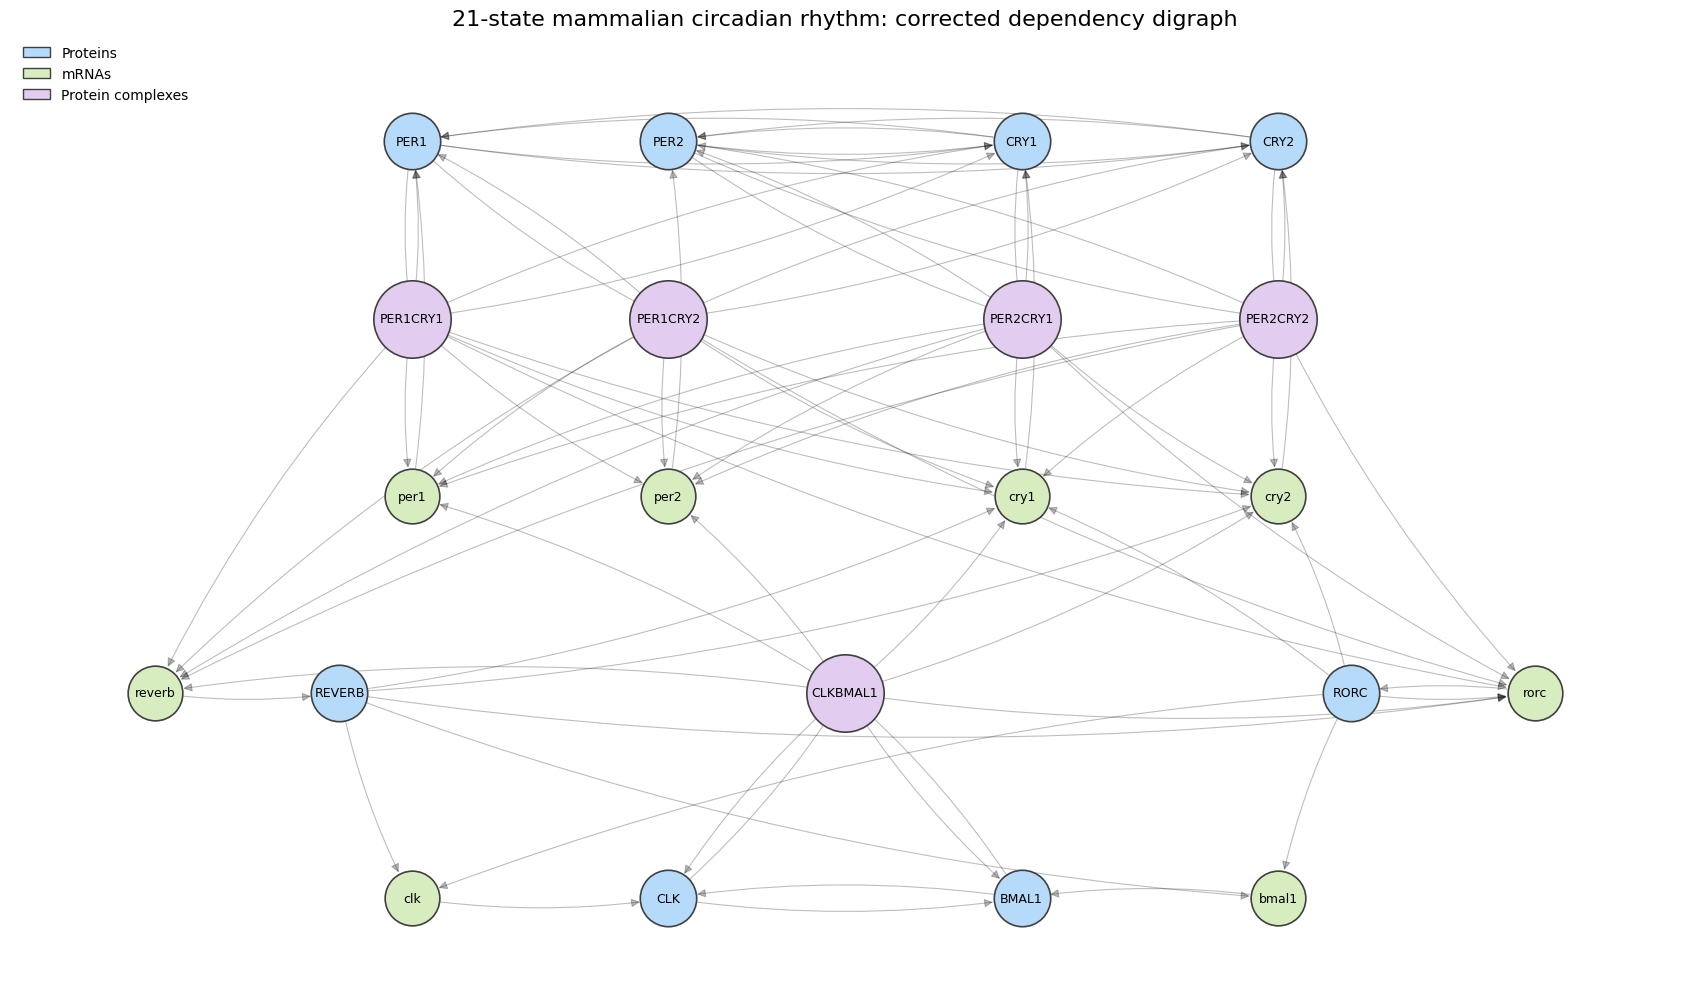

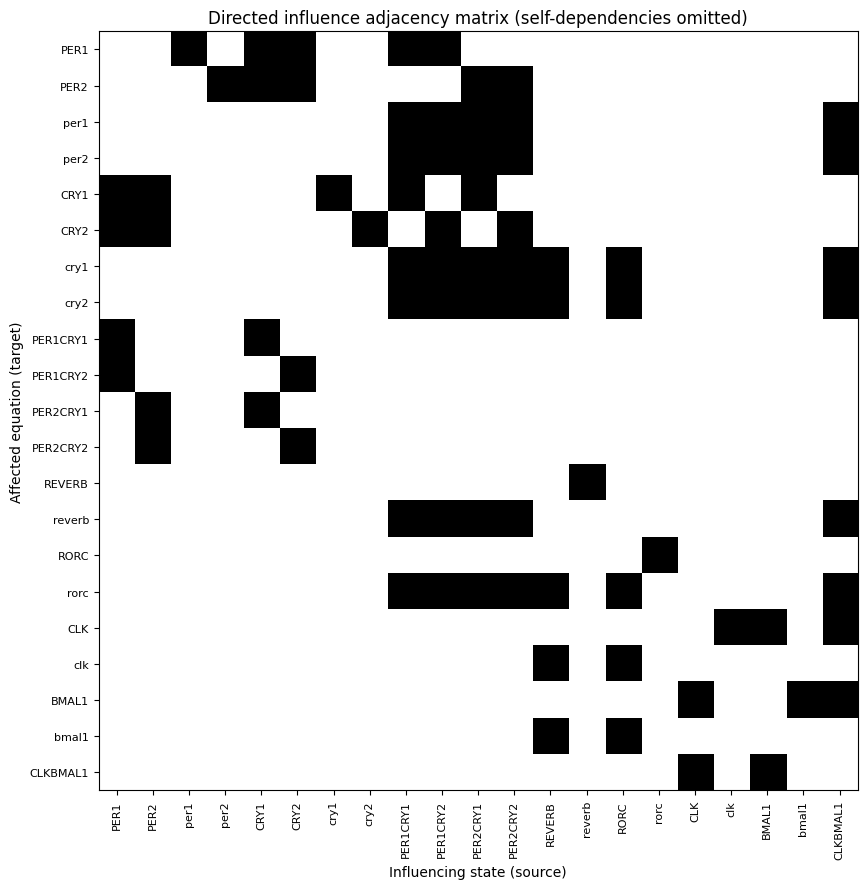

In [8]:
# A fixed, human-readable arrangement.  Every state occurs ONCE in the layout.
pos = {
    "PER1": (-2.7, 2.2), "PER2": (-1.1, 2.2), "CRY1": (1.1, 2.2), "CRY2": (2.7, 2.2),
    "PER1CRY1": (-2.7, 1.25), "PER1CRY2": (-1.1, 1.25),
    "PER2CRY1": (1.1, 1.25), "PER2CRY2": (2.7, 1.25),
    "per1": (-2.7, 0.3), "per2": (-1.1, 0.3), "cry1": (1.1, 0.3), "cry2": (2.7, 0.3),
    "reverb": (-4.3, -0.75), "REVERB": (-3.15, -0.75),
    "CLKBMAL1": (0, -0.75), "RORC": (3.15, -0.75), "rorc": (4.3, -0.75),
    "clk": (-2.7, -1.85), "CLK": (-1.1, -1.85),
    "BMAL1": (1.1, -1.85), "bmal1": (2.7, -1.85),
}
assert len(pos) == N and set(pos) == set(STATE_NAMES)
COMPLEXES = {"PER1CRY1", "PER1CRY2", "PER2CRY1", "PER2CRY2", "CLKBMAL1"}
MRNAS = {"per1", "per2", "cry1", "cry2", "reverb", "rorc", "clk", "bmal1"}
PROTEINS = set(STATE_NAMES) - COMPLEXES - MRNAS

fig, ax = plt.subplots(figsize=(17, 10))
nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=13, node_size=1700,
                       alpha=0.26, width=0.8, connectionstyle="arc3,rad=0.075")
for group, color, size in [(PROTEINS, "#b6dafa", 1650),
                           (MRNAS, "#d7edc0", 1550),
                           (COMPLEXES, "#e2ccef", 3100)]:
    nx.draw_networkx_nodes(G, pos, nodelist=sorted(group), node_size=size,
                           node_color=color, edgecolors="#404040", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="medium", ax=ax)
from matplotlib.patches import Patch
ax.set_title("21-state mammalian circadian rhythm: corrected dependency digraph", fontsize=16)
ax.legend(handles=[Patch(facecolor="#b6dafa", edgecolor="#404040", label="Proteins"),
                   Patch(facecolor="#d7edc0", edgecolor="#404040", label="mRNAs"),
                   Patch(facecolor="#e2ccef", edgecolor="#404040", label="Protein complexes")],
          loc="upper left", frameon=False, fontsize=10)
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "circadian_dependency_digraph.png", dpi=180, bbox_inches="tight")
plt.show()

# Adjacency matrix: row = equation affected, column = influencing state.
A = nx.to_numpy_array(G, nodelist=STATE_NAMES, dtype=int).T
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(A, cmap="Greys", interpolation="nearest", vmin=0, vmax=1)
ax.set_xticks(range(N), STATE_NAMES, rotation=90, fontsize=8)
ax.set_yticks(range(N), STATE_NAMES, fontsize=8)
ax.set_xlabel("Influencing state (source)")
ax.set_ylabel("Affected equation (target)")
ax.set_title("Directed influence adjacency matrix (self-dependencies omitted)")
fig.tight_layout()
fig.savefig(OUTPUT / "circadian_dependency_matrix.png", dpi=180)
plt.show()

## 5. Numerical FVS control

For each candidate FVS \(F\), we set \(x_i(0)=x_i^*\) for \(i\in F\), and clamp \(\dot x_i=0\) at those values for the entire simulated interval. All **uncontrolled** state variables start at zero. As a baseline, we also simulate the **fully uncontrolled model from the all-zero state**.

The primary integrator is SciPy's adaptive `DOP853` (eighth-order explicit Runge–Kutta with error control). This is more robust than blindly fixing the step size at `0.001`; an explicit RK4 implementation appears near the end to check the original Julia method. These tests are finite-time numerical experiments, not proofs about all initial conditions.

In [9]:
def state_indices(names):
    return np.array([STATE_INDEX[name] for name in names], dtype=int)


def controlled_rhs(t, x, controlled_indices):
    """Ideal constant state clamping: held states do not evolve."""
    dx = circadian_rhs(t, x)
    dx[controlled_indices] = 0.0
    return dx


def simulate(fvs=(), t_final=25.0, samples=2501, method="DOP853"):
    """Integrate one controlled experiment; `fvs=()` gives uncontrolled baseline."""
    idx = state_indices(fvs)
    x0 = np.zeros(N, dtype=float)
    x0[idx] = TARGET_EQUILIBRIUM[idx]
    rhs = lambda t, x: controlled_rhs(t, x, idx)
    t_eval = np.linspace(0.0, t_final, samples)
    sol = solve_ivp(rhs, (0.0, t_final), x0, method=method,
                    t_eval=t_eval, max_step=0.1, rtol=1e-9, atol=1e-11)
    if not sol.success:
        raise RuntimeError(f"ODE integration failed: {sol.message}")
    # Stored array has shape (samples, 21).
    X = sol.y.T.copy()
    if np.min(X) < -1e-9:
        raise AssertionError("Unexpected negative state in numerical trajectory")
    if len(idx):
        assert np.max(np.abs(X[:, idx] - TARGET_EQUILIBRIUM[idx])) < 1e-10
    return sol.t, X


def error_curves(X, target=TARGET_EQUILIBRIUM):
    """Max per-component relative error and full-state Euclidean distance."""
    if np.any(target <= 0):
        raise ValueError("Relative errors require a strictly positive target here")
    delta = X - target
    rel = np.max(np.abs(delta) / np.abs(target), axis=1)
    l2 = np.linalg.norm(delta, axis=1)
    return rel, l2


def last_entry_time(t, error, tolerance=0.01):
    """First sampled time after the FINAL tolerance violation.

    Returns NaN if the trajectory has not stayed within tolerance by the final
    sampled time. This is a finite-window, sampled-grid statistic, not proof
    of asymptotic convergence.
    """
    outside = np.flatnonzero(error > tolerance)
    if len(outside) == 0:
        return float(t[0])
    if outside[-1] == len(t) - 1:
        return float("nan")
    return float(t[outside[-1] + 1])

# Compare all six FVS control experiments with the uncontrolled baseline.
results = {}
summary_rows = []
for label, members in [("Uncontrolled", []), *[(f"FVS {i}", fs) for i, fs in enumerate(FVS_SETS, 1)]]:
    t, X = simulate(members)
    rel, dist = error_curves(X)
    results[label] = dict(t=t, X=X, rel=rel, l2=dist, members=members)
    summary_rows.append({
        "experiment": label,
        "clamped_states": len(members),
        "last_entry_time_1pct": last_entry_time(t, rel),
        "final_max_relative_error_pct": 100 * rel[-1],
        "final_euclidean_distance": dist[-1],
        "minimum_state_value": np.min(X),
    })
summary = pd.DataFrame(summary_rows)
display(summary)
summary.to_csv(OUTPUT / "circadian_fvs_summary.csv", index=False)
print("Saved", OUTPUT / "circadian_fvs_summary.csv")

,experiment,clamped_states,last_entry_time_1pct,final_max_relative_error_pct,final_euclidean_distance,minimum_state_value
0,Uncontrolled,0,NaN,115.608776,1.944432,0.0
1,FVS 1,7,24.90,0.979602,0.010227,0.0
2,FVS 2,7,21.83,0.519697,0.003828,0.0
3,FVS 3,7,21.83,0.519697,0.003816,0.0
4,FVS 4,7,24.90,0.979602,0.010227,0.0
5,FVS 5,7,21.83,0.519691,0.003828,0.0
6,FVS 6,7,21.83,0.519691,0.003816,0.0


Saved outputs/circadian_fvs_summary.csv


### What the error statistics actually mean

The maximum relative error is \(\max_i |x_i(t)-x_i^*|/x_i^*\). The 1% last-entry time is the first **sampled** time after which that error never again exceeds 1% **within the observed interval**. The Euclidean distance is \(\lVert x(t)-x^*\rVert_2\).

When a metric is `NaN`, the 1% threshold was not maintained through the end of the simulated time window. This alone says nothing about possible convergence at a later time.

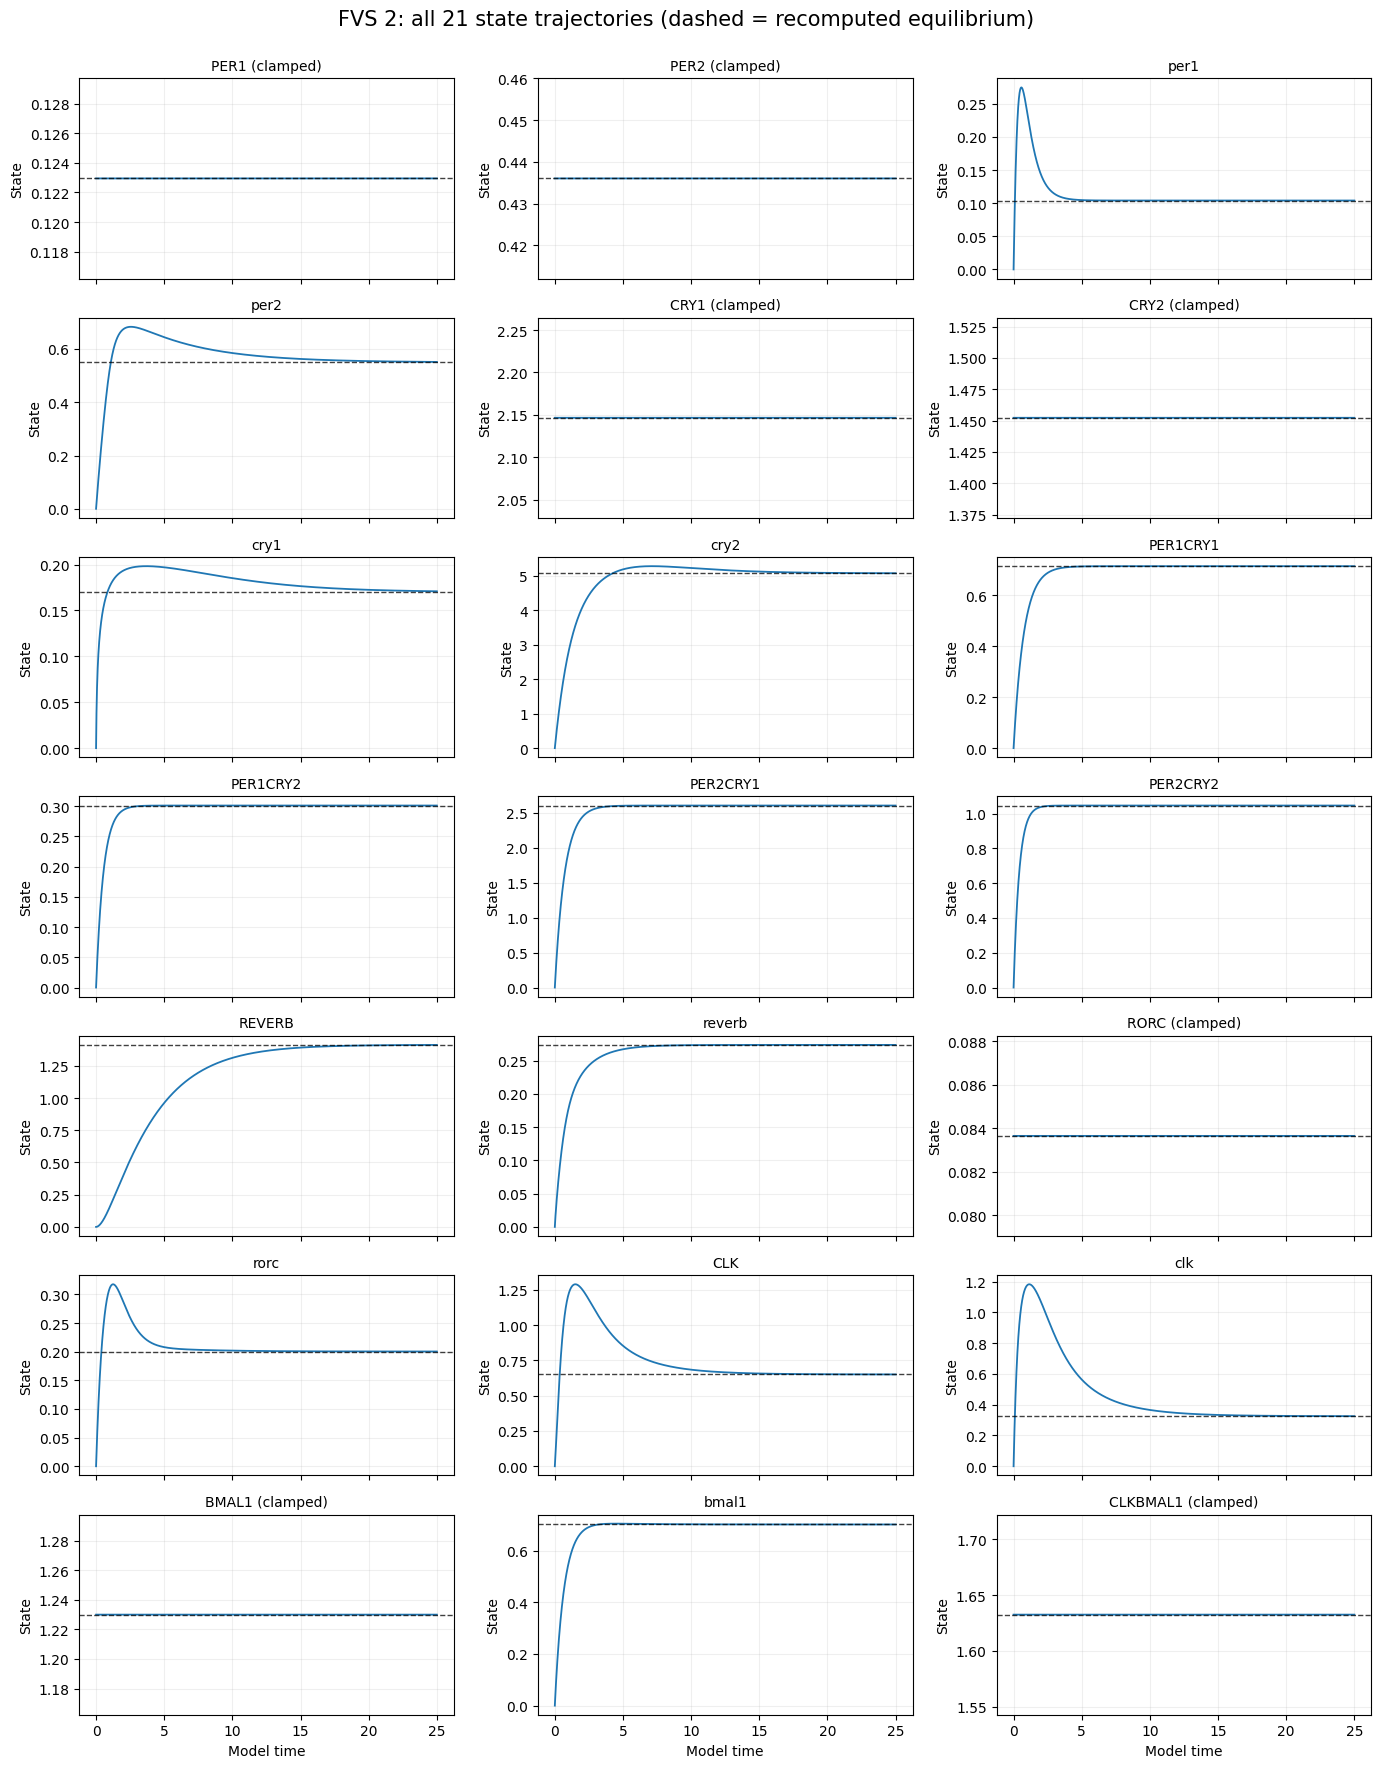

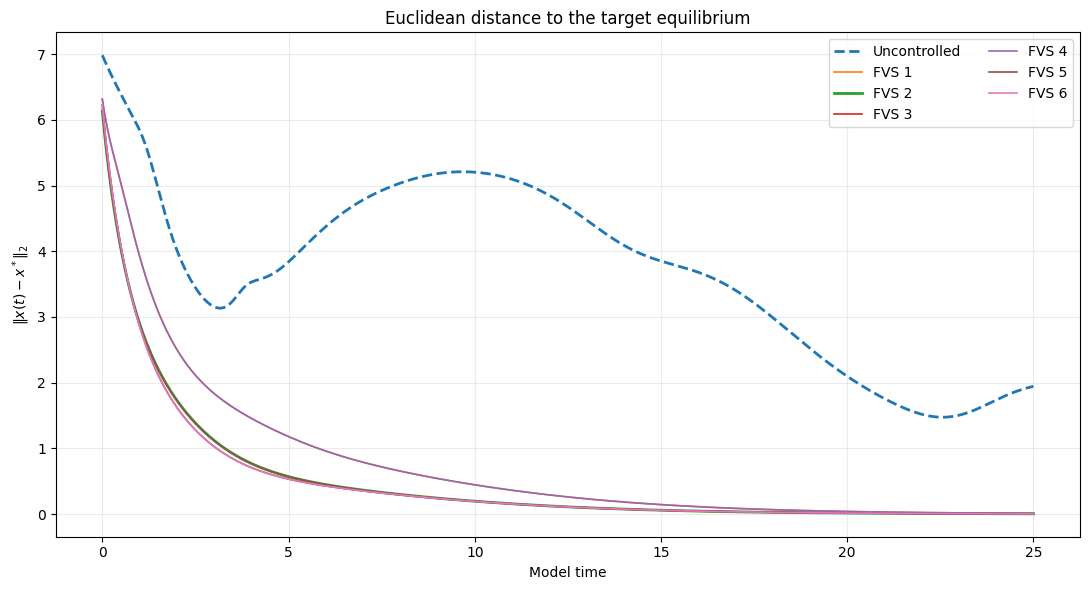

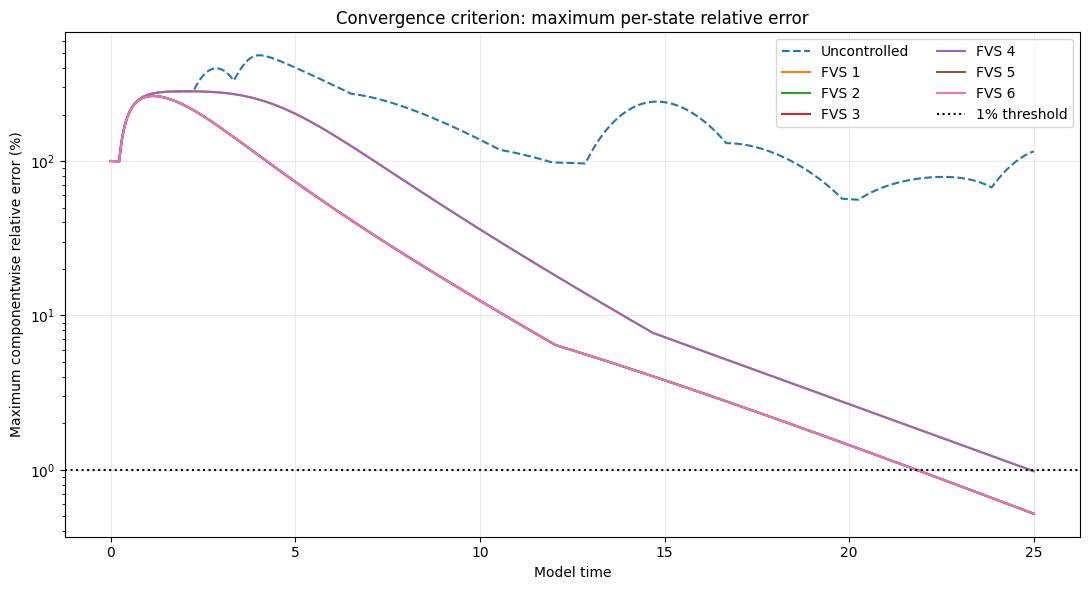

In [10]:
# Plot all 21 state trajectories for FVS 2, including the target equilibrium.
selection = "FVS 2"
r = results[selection]
fig, axes = plt.subplots(7, 3, figsize=(14, 18), sharex=True)
axes = axes.flatten()
for j, (ax, name) in enumerate(zip(axes, STATE_NAMES)):
    ax.plot(r["t"], r["X"][:, j], linewidth=1.3, label="Controlled trajectory")
    ax.axhline(TARGET_EQUILIBRIUM[j], linestyle="--", linewidth=1, color="black", alpha=0.75,
               label="Equilibrium")
    ax.set_title(name + (" (clamped)" if name in r["members"] else ""), fontsize=10)
    ax.grid(alpha=0.2)
    ax.set_ylabel("State")
for ax in axes[-3:]:
    ax.set_xlabel("Model time")
fig.suptitle("FVS 2: all 21 state trajectories (dashed = recomputed equilibrium)", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(OUTPUT / "circadian_fvs2_21_trajectories.png", dpi=180)
plt.show()

# Compare all controlled experiments against the uncontrolled run using a single norm.
fig, ax = plt.subplots(figsize=(11, 6))
for label, r in results.items():
    ax.plot(r["t"], r["l2"], linewidth=2 if label in ("Uncontrolled", "FVS 2") else 1.2,
            linestyle="--" if label == "Uncontrolled" else "-", label=label)
ax.set_xlabel("Model time")
ax.set_ylabel(r"$\|x(t)-x^*\|_2$")
ax.set_title("Euclidean distance to the target equilibrium")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "circadian_fvs_distance_comparison.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
for label, r in results.items():
    ax.plot(r["t"], 100*r["rel"],
            linestyle="--" if label == "Uncontrolled" else "-", label=label)
ax.axhline(1, color="black", ls=":", label="1% threshold")
ax.set_yscale("log")
ax.set_xlabel("Model time")
ax.set_ylabel("Maximum componentwise relative error (%)")
ax.set_title("Convergence criterion: maximum per-state relative error")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "circadian_fvs_relative_errors.png", dpi=180)
plt.show()

## 6. Cross-check against the original fixed-step RK4 approach

The uploaded Julia version used a classical fourth-order Runge–Kutta scheme. Here we implement RK4 separately and compare it with adaptive `DOP853` over a short interval. This is a **consistency check**, not a rigorous numerical error bound. The initial state is on the boundary of the positive orthant; some fractional Hill exponents yield poor smoothness there, so fixed-step RK4 error can decay **more slowly than fourth order**. We therefore check step refinement rather than asserting unrealistically small errors at a single step size.

In [11]:
def rk4_fixed_step(fvs=(), t_final=2.0, step=0.001):
    """Classical fixed-step RK4, analogous to the older Julia implementation."""
    nsteps = int(round(t_final / step))
    if not np.isclose(nsteps * step, t_final):
        raise ValueError("t_final must be an integer multiple of step")
    idx = state_indices(fvs)
    x = np.zeros(N, dtype=float)
    x[idx] = TARGET_EQUILIBRIUM[idx]
    t = np.linspace(0, t_final, nsteps + 1)
    X = np.empty((nsteps + 1, N))
    X[0] = x
    for k in range(nsteps):
        k1 = controlled_rhs(t[k], x, idx)
        k2 = controlled_rhs(t[k] + step/2, x + step*k1/2, idx)
        k3 = controlled_rhs(t[k] + step/2, x + step*k2/2, idx)
        k4 = controlled_rhs(t[k] + step, x + step*k3, idx)
        x = x + (step/6) * (k1 + 2*k2 + 2*k3 + k4)
        x[idx] = TARGET_EQUILIBRIUM[idx]  # enforce clamping up to roundoff
        X[k+1] = x
    return t, X

# With fractional Hill exponents, derivatives can be poorly conditioned at zero.
# Thus fixed-step RK4 need not show its ideal fourth-order convergence near t=0.
# We check that reducing dt improves agreement with the adaptive reference.
step_errors = []
for step in (0.002, 0.001, 0.0005):
    rk_t, rk_X = rk4_fixed_step(FVS_SETS[1], t_final=2.0, step=step)
    _, ad_X = simulate(FVS_SETS[1], t_final=2.0, samples=len(rk_t))
    error = float(np.max(np.abs(rk_X - ad_X)))
    step_errors.append(error)
    print(f"RK4 dt={step:.4g}: max absolute difference from DOP853 = {error:.3e}")
assert all(np.isfinite(step_errors)) and step_errors[2] < step_errors[1] < step_errors[0]
print("Step refinement improves agreement; do not infer formal order from this singular-start test.")


RK4 dt=0.002: max absolute difference from DOP853 = 8.120e-04


RK4 dt=0.001: max absolute difference from DOP853 = 4.000e-04


RK4 dt=0.0005: max absolute difference from DOP853 = 1.969e-04
Step refinement improves agreement; do not infer formal order from this singular-start test.


## 7. Interpretation and limitations

- The graph and six FVS candidates are verified **for this explicitly recorded dependency graph**; they do not establish the biological correctness of every parameter.
- The corrected `rorc` equation changes the equilibrium. The old rounded stationary vector should **not** be reused as the target for the corrected model.
- This is **idealized clamping to a constant equilibrium**, not arbitrary trajectory tracking, not a biologically realizable controller, and not a theorem guaranteeing global convergence.
- `last_entry_time_1pct` is a **finite-window and sample-grid measurement**.
- The `root` solve provides **one** numerically verified equilibrium, not uniqueness.
- The local Jacobian provides a **numerical local stability indication** for the uncontrolled system; it does not characterize all long-term trajectories.
- All plotted outputs and the CSV summary are written to the `outputs/` folder.

For reproducing the study or extending it to additional initial conditions, start with the cited original papers, verify model assumptions, and test solver/tolerance sensitivity.